Importing

In [7]:
import pandas as pd
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_fscore_support
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

Reading data

In [2]:
data = pd.read_csv('parkwise_dataset.csv')

Training the model

In [3]:
X = pd.get_dummies(data.drop(columns=['busyness_level']), columns=['district'])
y = data['busyness_level']
X_tr, X_tst, y_tr, y_tst = train_test_split(X, y, train_size=0.8, random_state=42)
model = RandomForestClassifier()
grid = {'max_depth': [2, 4, 6, 8], 'min_samples_split': [2, 4, 6, 8], 'n_estimators': [2, 4, 6, 8]}
grid_search = GridSearchCV(model, grid)
grid_search.fit(X_tr, y_tr)
model.set_params(**grid_search.best_params_)
model.fit(X_tr, y_tr)
y_pred = pd.Series(model.predict(X_tst))

Validating the model

,0,1,2,3
precision,0.851163,0.847021,0.877637,0.992308
recall,0.982111,0.819315,0.825397,0.874576
f1-score,0.911960,0.832937,0.850716,0.929730
support,559.000000,642.000000,504.000000,295.000000


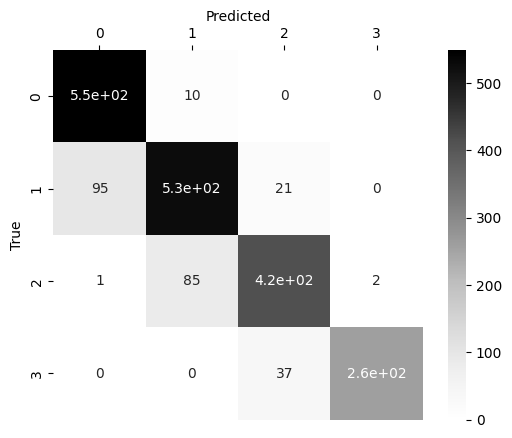

In [8]:
class_labels = model.classes_
cm = confusion_matrix(y_tst, y_pred)
disp = sns.heatmap(cm, square=True, annot=True, cbar=True, cmap="Greys", xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel("Predicted")
plt.ylabel("True")
disp.xaxis.set_label_position("top")
disp.xaxis.tick_top()
display(pd.DataFrame(precision_recall_fscore_support(y_true=y_tst, y_pred=y_pred),index=['precision', 'recall', 'f1-score', 'support'],columns=class_labels ))

Exporting the model

In [ ]:
joblib.dump(model, "random_forest_model.pkl")
joblib.dump(list(X.columns), "X_columns.pkl")

Data analysis report

1. Target Variable Description

The target variable in this project is busyness_level.

This variable represents the level of busyness in a district at a given moment in time.
It is a categorical variable with four possible classes:
	0 – Very low busyness,
	1 – Low busyness,
	2 – Moderate busyness,
	3 – High busyness,

The goal of the model is to predict the busyness level for each district based on temporal and environmental factors.

This makes the task a multi-class classification problem.

2. Predictors Description

The predictors (features) used to train the model are:
Time-related features:
	Hour of the day,
	Day of the week,
Weather-related features:
	Temperature,
	Precipitation,
	Wind speed,
Location feature:
	District (categorical)

All predictors were chosen because they are expected to influence human activity and therefore the busyness level.

3. Training Set Description

The training dataset was compiled from historical observations containing:
	Timestamp information,
	Weather data,
	District information,
	Observed busyness levels

The dataset was cleaned and prepared, after which 80% of the data was used as the training set.

The training set was used to fit the machine learning model and learn patterns between the predictors and the target variable.

4. Test Set Description

The remaining 20% of the data was used as the test set.

The test set was kept completely separate from the training process and was only used after training to evaluate the final performance of the model.

This ensures an unbiased evaluation of how well the model generalizes to unseen data.

5. Data Preparation

Several data preparation steps were applied:
	Conversion of categorical variables using One-Hot Encoding,
	Ensuring consistent feature ordering

No manual scaling was required since the final model (Random Forest) is not sensitive to feature scaling.

6. Data Exploration

Before training the machine learning models, an exploratory analysis of the dataset was performed to better understand the structure and characteristics of the data.

First, the distribution of the target variable (busyness_level) was examined to check for class imbalance. This analysis showed that all busyness levels were sufficiently represented, although some classes occurred more frequently than others.

Next, the temporal features were explored by analyzing how busyness varied across hours of the day and days of the week. Clear patterns were observed, indicating higher busyness during specific time periods, which confirmed the relevance of time-based predictors.

The district variable was analyzed to understand differences in busyness across locations. This showed that certain districts consistently exhibited higher activity levels, reinforcing the importance of including district information in the model.

Finally, basic correlation analysis was conducted between weather variables and busyness levels. While individual weather features showed limited linear correlation, combined effects appeared relevant, supporting the choice of a non-linear model.

This exploratory analysis guided the feature selection and modeling decisions used in the subsequent steps.

7. Training

Multiple models were trained and compared:

Models used:
	Decision Tree Classifier,
	Random Forest Classifier (final model)

The Random Forest model was selected because:
	It handles non-linear relationships well,
	It works effectively with mixed feature types,
	It showed the best validation performance

The final model was trained using the training dataset with optimized hyperparameters.

8. Validation

Model validation was performed using:
	Train/test split,
	Hyperparameter tuning,
	Confusion matrix,
	Accuracy score

The Random Forest model achieved the highest accuracy among the tested models.

A confusion matrix was used to evaluate classification performance across all busyness levels, showing strong predictive power with limited misclassification between adjacent classes.

Validation results confirm that the model generalizes well to unseen data.

9. Conclusion

The project resulted in a working and deployable machine learning model capable of predicting busyness levels per district.

Strengths:
	Good classification performance,
	Handles real-time input data,
	Successfully integrated into a web application

Possible Improvements:
	Collect more data to improve class balance,
	Include additional predictors,
	Evaluate more advanced models

Overall, the model meets the project requirements and provides reliable predictions for practical use.
